In [ ]:
!pip install ipywidgets
!pip install mne
!pip install numpy matplotlib scipy  # Install dependencies first
!pip install python-picard


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for python-picard: filename=python_picard-0.8-py3-none-any.whl size=16394 sha256=c7eef0b3a782ac866f7cb75ac05e5ca76836a37ba85bbe0f578c897cdde8b43b
  Stored in directory: /root/.cache/pip/wheels/86/7e/fc/6183c6bfdc791d9e7b5a1df84ec4f30055f76bc8414ab2300d
Successfully built python-picard


In [ ]:
import pandas as pd
import numpy as np
import mne
import matplotlib.pyplot as plt
from ipywidgets import interact, Dropdown, Text, VBox, HBox, Checkbox, IntSlider
from scipy import signal
from scipy.signal import decimate

In [ ]:
fileUpload = Text(value='data.bdf', description='File Path:')
downsampleOnOff = Checkbox(value=True, description='Downsample')
# downsampleDropdown = Dropdown(options=['128', '256', '512'], value='128', description='Downsample Rate:')
downsamplebar = IntSlider(value=2, min=1, max=10, step=1, description='Factor Samplerate:', orientation='horizontal')
bandpassOnOff = Checkbox(value=True, description='Bandpass Filter')
icaMethod = Dropdown(options=['fastica', 'infomax', 'picard'], value='picard', description='ICA Method:')
icaOnOff = Checkbox(value=True, description='ICA')
ui = VBox([
    fileUpload,
    HBox([downsampleOnOff, downsamplebar]),
    bandpassOnOff,
    HBox([icaOnOff, icaMethod])
])
display(ui)

# Layered Architecture



### Dataloader

In [ ]:
class Dataloader:
  def getData(self, fileUpload):
    raw = mne.io.read_raw_bdf(fileUpload, preload=True).pick('eeg') #may need to tweak preload to False when handling a large dataset
    raw_eeg = raw.copy()
    return raw_eeg



### PreProcessing


In [ ]:
class Preprocessing:
  def __init__(self, icaMethod, randSeed, nComponents = 32):
    self.ica = mne.preprocessing.ICA(nComponents, random_state=randSeed, max_iter='auto', method = icaMethod.value)

  def preprocess(self, rawEegData, downsampleTrue, downsamplerate, bandpassTrue, icaTrue, icaMethod):

    #BandPass Filter
    if(bandpassTrue == True):
      rawEegBandpass = rawEegData.copy().filter(l_freq=4.0, h_freq=45.0) #can add in extra feature for bandpass range | range 4 - 45 comes from the bandpass filter that deap use
      if(icaOnOff.value == True): #ICA with bandpass
        self.ica.fit(rawEegBandpass)
      eegData, times = rawEegBandpass.get_data(return_times=True)
    else:
      if(icaOnOff.value == True): #ICA without bandpass
        self.ica.fit(rawEegData) # Pass the raw object instead of raw.get_data
      eegData, times = rawEegData.get_data(return_times=True) # Get data from rawEegData

    #Downsampling
    dataArray = eegData
    if(downsampleTrue == True):
      factor = downsamplebar.value                                                 #This needs automisation, can get data sample rate with raw.info['sfreq']
      downsampled_data = np.zeros((len(dataArray), len(dataArray[0]) // factor))
      for i in range(len(dataArray)):
        downsampled_data[i] = decimate(dataArray[i], factor, ftype='fir')
      dataArray = downsampled_data


    return dataArray

# Testing and Running


In [ ]:
RANDSEED = 52
dataloader = Dataloader()
raw = dataloader.getData(fileUpload.value)
nonEEGChannels = [ #so, the mne.pick("eeg") that should work for this wont because the metadata doesnt label the data as eeg, so I am manually removing these channels for now...will need to be automated better for custom datasets
    'EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8',
    'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'
]
raw.drop_channels(nonEEGChannels)
NCOMPONENTS = len(raw.ch_names)


Extracting EDF parameters from /content/s01.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...


/tmp/ipython-input-3303846579.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_bdf(fileUpload, preload=True).pick('eeg') #may need to tweak preload to False when handling a large dataset


Reading 0 ... 691199  =      0.000 ...  1349.998 secs...


In [ ]:
preProcessor = Preprocessing(randSeed = RANDSEED, nComponents = NCOMPONENTS, icaMethod = icaMethod)
preProcessedData = preProcessor.preprocess(rawEegData = raw, downsampleTrue = downsampleOnOff.value,downsamplerate = downsamplebar, bandpassTrue = bandpassOnOff.value, icaTrue = icaOnOff.value, icaMethod = icaMethod)
preProcessedData

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples (1.650 s)

Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 32 components
Fitting ICA took 136.8s.


array([[ 3.20232264e-06,  3.26852343e-05,  4.15438068e-05, ...,
         1.54288427e-05,  1.30371540e-05,  4.42939992e-06],
       [ 1.60038137e-06,  1.72463978e-05,  2.54471939e-05, ...,
         1.56670933e-05,  1.29697608e-05,  4.38304842e-06],
       [ 2.43352979e-06,  2.51521544e-05,  3.31774160e-05, ...,
         1.90261668e-05,  1.70308072e-05,  5.94834769e-06],
       ...,
       [ 2.25843191e-06,  2.24474603e-05,  2.61780875e-05, ...,
         1.07064492e-05,  4.76738423e-06,  8.53882177e-07],
       [ 2.05290429e-06,  2.02057333e-05,  2.28345034e-05, ...,
         6.73232163e-06,  1.02223924e-06, -5.06893244e-07],
       [ 1.85550390e-06,  1.79793053e-05,  1.92170056e-05, ...,
         6.38036769e-06, -2.52299781e-07, -1.11926226e-06]])

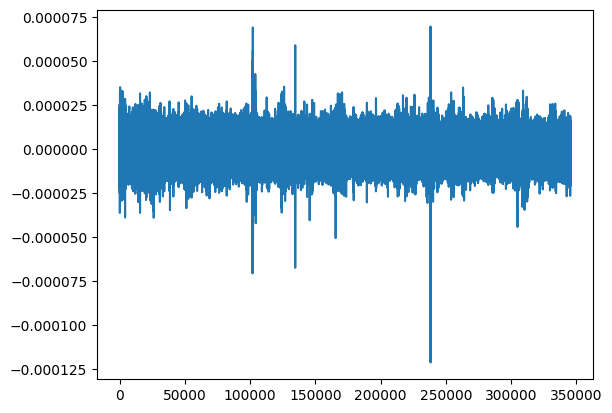

In [ ]:
plt.plot(preProcessedData[1])

In [ ]:
downsampled = decimate(eegData[0],2, ftype='fir') #factor of 2 on the DEAP data takes it from 512Hz -> 256Hz (new samplerate = 512Hz/factor)
plt.plot(downsampled)

NameError: name 'eegData' is not defined

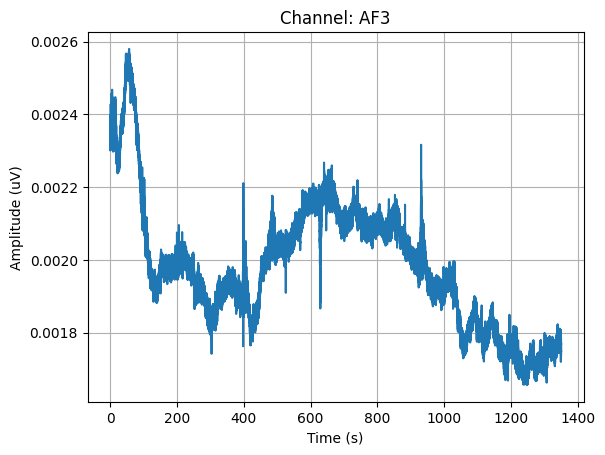

In [ ]:
raw_eeg = raw.copy().pick('eeg')
eeg_data, times = raw_eeg.get_data(return_times=True)


plt.plot(times, eeg_data[1])  #plot first EEG channel
plt.title(f"Channel: {raw_eeg.ch_names[1]}")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (uV)")
plt.grid(True)
plt.show()